# ALNS Experimental Results Analysis

This notebook analyzes the **20 MD-DARP instances x 20 random seeds** from the base ALNS experiment.

It is intentionally broad: it produces more tables and figures than are likely to be included in the paper, so that the most informative results can be selected later.

The analysis covers:

1. Run-level solution quality and runtime.
2. Final performance across all 20 instances.
3. Convergence behaviour, both for individual instances and aggregated.
4. Destroy/repair operator selection frequencies.
5. Destroy-repair pair frequencies and collective rewards.
6. Evolution of adaptive operator weights.
7. Operator behaviour by time-window regime (`a` vs. `b`) and instance size.
8. Final-solution information from the JSON output files.
9. Optional CSV exports of the main analysis tables.

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

BASE_DIR = Path("../data/run_base_20")
LOG_DIR = BASE_DIR / "alns_logs"
OUTPUT_DIR = BASE_DIR / "outputs"

EXPECTED_INSTANCES = [
    "md1a", "md2a", "md3a", "md4a", "md5a",
    "md6a", "md7a", "md8a", "md9a", "md10a",
    "md1b", "md2b", "md3b", "md4b", "md5b",
    "md6b", "md7b", "md8b", "md9b", "md10b",
]

EXPECTED_SEEDS = range(1, 21)

DESTROY_METHODS = {
    0: "Random",
    1: "Worst",
    2: "Shaw",
}

REPAIR_METHODS = {
    0: "Greedy",
    1: "Regret-2",
    2: "Regret-3",
}

# Output directory for optional analysis tables/figures
ANALYSIS_DIR = Path("../results/base_20")
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Plot configuration
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["figure.dpi"] = 120

print(f"Log directory:    {LOG_DIR.resolve()}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")


Log directory:    /home/guillem/MD-DARP-Research-clean/experiments/data/run_base_20/alns_logs
Output directory: /home/guillem/MD-DARP-Research-clean/experiments/data/run_base_20/outputs


## 1. Discover and load all runs

The loader uses the filenames

- `log_{instance}_seed{seed}_convergence.csv`
- `log_{instance}_seed{seed}_weights_evolution.csv`
- `sol_{instance}_seed{seed}.json`

and does not assume that every run has exactly the same number of iterations.


In [2]:
# ---------------------------------------------------------
# File discovery
# ---------------------------------------------------------

conv_files = sorted(LOG_DIR.glob("log_*_seed*_convergence.csv"))
weight_files = sorted(LOG_DIR.glob("log_*_seed*_weights_evolution.csv"))
solution_files = sorted(OUTPUT_DIR.glob("sol_*_seed*.json"))

print(f"Convergence logs found: {len(conv_files)}")
print(f"Weight logs found:      {len(weight_files)}")
print(f"Solution JSONs found:   {len(solution_files)}")

# Extract instance and seed from a filename
filename_pattern = re.compile(r"log_(.+)_seed(\d+)_convergence\.csv$")

def parse_log_filename(path):
    match = filename_pattern.match(path.name)
    if not match:
        return None, None
    return match.group(1), int(match.group(2))

discovered_runs = sorted(
    [parse_log_filename(p) for p in conv_files if parse_log_filename(p)[0] is not None]
)

print(f"Unique convergence runs: {len(discovered_runs)}")

missing_expected = [
    (inst, seed)
    for inst in EXPECTED_INSTANCES
    for seed in EXPECTED_SEEDS
    if (inst, seed) not in discovered_runs
]

unexpected_runs = [
    run for run in discovered_runs
    if run[0] not in EXPECTED_INSTANCES or run[1] not in EXPECTED_SEEDS
]

if missing_expected:
    print("\nMissing expected runs:")
    print(missing_expected[:30])
    if len(missing_expected) > 30:
        print(f"... and {len(missing_expected) - 30} more")

if unexpected_runs:
    print("\nUnexpected runs:")
    print(unexpected_runs[:30])

if not missing_expected and not unexpected_runs:
    print("All expected 20 x 20 = 400 convergence runs were found.")


Convergence logs found: 400
Weight logs found:      400
Solution JSONs found:   400
Unique convergence runs: 400
All expected 20 x 20 = 400 convergence runs were found.


In [3]:
# ---------------------------------------------------------
# Load convergence logs into one long dataframe
# ---------------------------------------------------------

required_conv_columns = {
    "iteration",
    "elapsed_time",
    "current_obj",
    "best_obj",
    "best_feasible_obj",
    "destroy_op",
    "repair_op",
    "reward",
    "temperature",
    "segment",
}

conv_frames = []

for path in conv_files:
    instance, seed = parse_log_filename(path)
    if instance is None:
        continue

    try:
        df = pd.read_csv(path)
    except Exception as exc:
        warnings.warn(f"Could not read {path}: {exc}")
        continue

    missing_cols = required_conv_columns - set(df.columns)
    if missing_cols:
        warnings.warn(f"{path.name}: missing columns {sorted(missing_cols)}")
        continue

    df["instance"] = instance
    df["seed"] = seed
    df["run_id"] = f"{instance}_seed{seed}"

    # Convert numerical columns safely.
    numeric_cols = [
        "iteration", "elapsed_time", "current_obj", "best_obj",
        "best_feasible_obj", "destroy_op", "repair_op", "reward",
        "temperature", "segment"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Infinite objective values represent unavailable feasible solutions.
    df["best_feasible_obj"] = df["best_feasible_obj"].replace(
        [np.inf, -np.inf], np.nan
    )

    conv_frames.append(df)

df_conv_all = pd.concat(conv_frames, ignore_index=True)

print(f"Loaded {df_conv_all['run_id'].nunique()} runs.")
print(f"Total log rows: {len(df_conv_all):,}")
display(df_conv_all.head())


Loaded 400 runs.
Total log rows: 3,998,602


,iteration,elapsed_time,current_obj,best_obj,best_feasible_obj,destroy_op,repair_op,reward,temperature,segment,instance,seed,run_id
0,0,1.11795,17563.80,17563.80,NaN,0,2,29.4073,15530.0,0,md10a,10,md10a_seed10
1,1,1.55677,18840.70,17563.80,NaN,0,0,22.0589,15516.0,0,md10a,10,md10a_seed10
2,2,2.38554,8857.06,8857.06,NaN,0,1,29.4073,15502.1,0,md10a,10,md10a_seed10
3,3,2.78401,8857.06,8857.06,NaN,1,0,0.0000,15488.1,0,md10a,10,md10a_seed10
4,4,3.56454,6632.97,6632.97,NaN,1,1,29.4073,15474.2,0,md10a,10,md10a_seed10


In [4]:
# ---------------------------------------------------------
# Load weights logs
# ---------------------------------------------------------

weight_pattern = re.compile(r"log_(.+)_seed(\d+)_weights_evolution\.csv$")

def parse_weight_filename(path):
    match = weight_pattern.match(path.name)
    if not match:
        return None, None
    return match.group(1), int(match.group(2))

weight_frames = []

for path in weight_files:
    instance, seed = parse_weight_filename(path)
    if instance is None:
        continue

    try:
        df = pd.read_csv(path)
    except Exception as exc:
        warnings.warn(f"Could not read {path}: {exc}")
        continue

    required_weight_columns = {
        "segment", "elapsed_time",
        "destroy_weight_0", "destroy_weight_1", "destroy_weight_2",
        "repair_weight_0", "repair_weight_1", "repair_weight_2",
    }

    missing_cols = required_weight_columns - set(df.columns)
    if missing_cols:
        warnings.warn(f"{path.name}: missing columns {sorted(missing_cols)}")
        continue

    df["instance"] = instance
    df["seed"] = seed
    df["run_id"] = f"{instance}_seed{seed}"

    for col in required_weight_columns - {"segment"}:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["segment"] = pd.to_numeric(df["segment"], errors="coerce")

    weight_frames.append(df)

if weight_frames:
    df_weights_all = pd.concat(weight_frames, ignore_index=True)
else:
    df_weights_all = pd.DataFrame()

print(f"Loaded {df_weights_all['run_id'].nunique() if not df_weights_all.empty else 0} weight-log runs.")
print(f"Total weight rows: {len(df_weights_all):,}")


Loaded 400 weight-log runs.
Total weight rows: 39,992


## 2. Load final solution information from JSON

The JSON files are used as an additional source of final-solution information.

The loader looks for:

- `summary.objective`
- `summary.time_sec`
- `summary.status`
- `summary.mip_gap`
- `summary.num_requests`
- `summary.num_vehicles`

These values are kept separate from the convergence-log metrics so that discrepancies can be detected rather than silently overwritten.


In [5]:
# ---------------------------------------------------------
# Load solution JSON summaries
# ---------------------------------------------------------

solution_pattern = re.compile(r"sol_(.+)_seed(\d+)\.json$")

def parse_solution_filename(path):
    match = solution_pattern.match(path.name)
    if not match:
        return None, None
    return match.group(1), int(match.group(2))

solution_rows = []

for path in solution_files:
    instance, seed = parse_solution_filename(path)
    if instance is None:
        continue

    try:
        with open(path, "r") as f:
            data = json.load(f)
    except Exception as exc:
        warnings.warn(f"Could not read {path}: {exc}")
        continue

    summary = data.get("summary", {}) if isinstance(data, dict) else {}

    solution_rows.append({
        "instance": instance,
        "seed": seed,
        "run_id": f"{instance}_seed{seed}",
        "json_objective": summary.get("objective"),
        "json_time_sec": summary.get("time_sec"),
        "status": summary.get("status"),
        "mip_gap": summary.get("mip_gap"),
        "num_requests": summary.get("num_requests"),
        "num_vehicles": summary.get("num_vehicles"),
    })

df_solutions = pd.DataFrame(solution_rows)

if not df_solutions.empty:
    for col in [
        "json_objective", "json_time_sec", "mip_gap",
        "num_requests", "num_vehicles"
    ]:
        df_solutions[col] = pd.to_numeric(df_solutions[col], errors="coerce")

print(f"Solution JSONs loaded: {len(df_solutions)}")

Solution JSONs loaded: 400


## 3. Run-level summary

Each row below represents one `(instance, seed)` run.

This is the main dataset for statistically aggregating results without accidentally giving more weight to instances with more log rows.


In [6]:
# ---------------------------------------------------------
# Build one summary row per run
# ---------------------------------------------------------

run_rows = []

for run_id, g in df_conv_all.groupby("run_id", sort=False):
    g = g.sort_values("iteration")

    feasible = g["best_feasible_obj"].dropna()

    row = {
        "run_id": run_id,
        "instance": g["instance"].iloc[0],
        "seed": int(g["seed"].iloc[0]),
        "iterations": len(g),
        "elapsed_time_sec": g["elapsed_time"].max(),
        "initial_objective": g["current_obj"].iloc[0],
        "final_current_objective": g["current_obj"].iloc[-1],
        "best_objective": g["best_obj"].min(),
        "best_feasible_objective": feasible.min() if not feasible.empty else np.nan,
        "best_iteration": g.loc[g["best_obj"].idxmin(), "iteration"],
        "best_time_sec": g.loc[g["best_obj"].idxmin(), "elapsed_time"],
        "final_temperature": g["temperature"].iloc[-1],
        "segments": g["segment"].max() + 1 if g["segment"].notna().any() else np.nan,
    }

    run_rows.append(row)

df_runs = pd.DataFrame(run_rows)

# Merge JSON summary if available.
if not df_solutions.empty:
    df_runs = df_runs.merge(
        df_solutions,
        on=["run_id", "instance", "seed"],
        how="left"
    )

print(f"Run-level observations: {len(df_runs)}")
display(df_runs.head())


Run-level observations: 400


,run_id,instance,seed,iterations,elapsed_time_sec,initial_objective,final_current_objective,best_objective,best_feasible_objective,best_iteration,best_time_sec,final_temperature,segments,json_objective,json_time_sec,status,mip_gap,num_requests,num_vehicles
0,md10a_seed10,md10a,10,9850,7200.06,17563.8,1205.87,1199.10,1199.10,9009,6552.18,2.18680,99,1199.09961,7200.066107,Feasible,0.0,144,12
1,md10a_seed11,md10a,11,10000,5276.09,29967.3,1195.37,1194.27,1194.27,9873,5202.23,1.90977,100,1194.26768,5276.097734,Feasible,0.0,144,12
2,md10a_seed12,md10a,12,10000,5367.23,13008.4,1204.41,1201.24,1201.24,9844,5278.96,1.55427,100,1201.23744,5367.235211,Feasible,0.0,144,12
3,md10a_seed13,md10a,13,10000,5319.69,43401.0,1191.04,1182.02,1182.02,8360,4386.67,2.20483,100,1182.02151,5319.694539,Feasible,0.0,144,12
4,md10a_seed14,md10a,14,10000,5259.26,16201.1,1214.09,1213.64,1213.64,9850,5178.56,1.72854,100,1213.64328,5259.263398,Feasible,0.0,144,12


## 4. Instance-level summary

The following table aggregates the 20 seeds for each instance.

The primary statistics are based on the **best feasible objective found during each run**. This avoids mixing intermediate infeasible solutions with the final solution-quality analysis.


In [7]:
# ---------------------------------------------------------
# Instance-level performance summary
# ---------------------------------------------------------

def safe_mean(x):
    return x.mean() if x.notna().any() else np.nan

instance_summary = (
    df_runs
    .groupby("instance")
    .agg(
        n_requests=("num_requests", "first"),
        n_vehicles=("num_vehicles", "first"),
        runs=("seed", "count"),
        feasible_runs=("best_feasible_objective", lambda x: x.notna().sum()),
        best_objective=("best_feasible_objective", "min"),
        mean_objective=("best_feasible_objective", "mean"),
        median_objective=("best_feasible_objective", "median"),
        std_objective=("best_feasible_objective", "std"),
        mean_runtime_sec=("elapsed_time_sec", "mean"),
        median_runtime_sec=("elapsed_time_sec", "median"),
        std_runtime_sec=("elapsed_time_sec", "std"),
        mean_iterations=("iterations", "mean"),
        mean_best_time_sec=("best_time_sec", "mean"),
    )
    .reset_index()
)

instance_summary["regime"] = instance_summary["instance"].str[-1].str.upper()
instance_summary["size_id"] = (
    instance_summary["instance"]
    .str.extract(r"md(\d+)[ab]", expand=False)
    .astype(int)
)

instance_summary = instance_summary.sort_values("size_id")

display(instance_summary.round(4))


,instance,n_requests,n_vehicles,runs,feasible_runs,best_objective,mean_objective,median_objective,std_objective,mean_runtime_sec,median_runtime_sec,std_runtime_sec,mean_iterations,mean_best_time_sec,regime,size_id
2,md1a,24,3,20,20,308.567,308.6872,308.7010,0.1265,47.0081,43.9968,7.4203,10000.0,10.6999,A,1
3,md1b,24,3,20,20,255.980,256.0268,255.9800,0.0852,56.8055,55.3563,6.9473,10000.0,13.9523,B,1
4,md2a,48,5,20,20,530.014,539.1624,538.5550,5.9531,303.5915,278.9860,57.0419,10000.0,183.0458,A,2
5,md2b,48,5,20,20,462.524,472.9162,474.3535,5.0458,341.0831,304.8370,62.8747,10000.0,170.5695,B,2
6,md3a,72,7,20,20,683.610,695.1800,695.3465,7.5947,880.2236,810.7110,149.6177,10000.0,659.5824,A,3
7,md3b,72,7,20,20,605.855,626.0101,625.5820,11.8691,1134.9466,1232.7000,203.6585,10000.0,691.8192,B,3
9,md4b,96,9,20,20,773.215,791.8124,792.6685,7.4693,1908.8855,1756.6300,303.3283,10000.0,1478.9059,B,4
8,md4a,96,9,20,20,825.669,840.1404,841.5870,9.5804,1832.0860,1752.3550,249.4625,10000.0,1250.8838,A,4
10,md5a,120,11,20,20,980.301,1016.9892,1017.6900,17.6183,3041.1880,2807.0050,499.0949,10000.0,2589.0600,A,5
11,md5b,120,11,20,20,878.719,902.6376,902.5210,11.8315,3409.1410,3030.7000,618.1372,10000.0,2790.6770,B,5


## 5. Best-found reference and RPD

For the exploratory analysis, the reference value for each instance is the **best feasible objective observed across the 20 seeds in this experiment**.

This is an internal experimental reference, not a proven optimum.

RPD is then computed per run:

$$
\mathrm{RPD}_{i,s}
=
100\frac{z_{i,s}-z_i^{best}}{z_i^{best}}.
$$

This makes comparisons across instances of different sizes easier.


In [8]:
import warnings
import numpy as np
from utils import BKR

# ---------------------------------------------------------
# RPD relative to BKR, with feasibility / BKR checks
# ---------------------------------------------------------
df_runs["bkr"] = df_runs["instance"].map(BKR)

# Check 1: instances without a BKR
missing_bkr = sorted(df_runs.loc[df_runs["bkr"].isna(), "instance"].unique())
if missing_bkr:
    warnings.warn(f"No BKR found for instances: {missing_bkr}")

# Check 2: infeasible / NaN / infinite runs
bad = ~np.isfinite(df_runs["best_feasible_objective"].astype(float))
if bad.any():
    id_cols = [c for c in ["run_id", "instance", "seed"] if c in df_runs.columns]
    warnings.warn(
        f"{bad.sum()} run(s) have no feasible solution (NaN/inf objective):\n"
        + df_runs.loc[bad, id_cols].to_string(index=False)
    )

df_runs["RPD_percent"] = (
    100 * (df_runs["best_feasible_objective"] - df_runs["bkr"]) / df_runs["bkr"]
)

instance_rpd_summary = (
    df_runs
    .groupby("instance")
    .agg(
        mean_RPD=("RPD_percent", "mean"),
        median_RPD=("RPD_percent", "median"),
        std_RPD=("RPD_percent", "std"),
        best_RPD=("RPD_percent", "min"),
        worst_RPD=("RPD_percent", "max"),
    )
    .reset_index()
)

instance_rpd_summary["size_id"] = (
    instance_rpd_summary["instance"]
    .str.extract(r"md(\d+)[ab]", expand=False)
    .astype(int)
)
instance_rpd_summary["regime"] = (
    instance_rpd_summary["instance"].str[-1].str.upper()
)

display(instance_rpd_summary.round(4))

,instance,mean_RPD,median_RPD,std_RPD,best_RPD,worst_RPD,size_id,regime
0,md10a,4.1151,4.3033,1.5761,-0.0003,6.1799,10,A
1,md10b,3.8286,3.5674,1.1932,1.4089,5.8322,10,B
2,md1a,0.0390,0.0434,0.0410,0.0000,0.1854,1,A
3,md1b,0.0183,0.0000,0.0333,0.0000,0.0902,1,B
4,md2a,2.5808,2.4652,1.1326,0.8402,4.5394,2,A
5,md2b,2.7715,3.0838,1.0965,0.5131,4.1907,2,B
6,md3a,2.4182,2.4427,1.1189,0.7136,4.6758,3,A
7,md3b,3.4127,3.3420,1.9607,0.0833,6.9665,3,B
8,md4a,2.0281,2.2038,1.1635,0.2707,5.0188,4,A
9,md4b,2.4052,2.5159,0.9660,0.0000,3.8781,4,B


## 6. Main performance table

This is a candidate table for the paper. It is deliberately compact and can be reduced further later.


In [9]:
# ---------------------------------------------------------
# Candidate main performance table
# ---------------------------------------------------------

main_table = (
    instance_summary[
        [
            "instance", "n_requests", "n_vehicles", "regime",
            "best_objective", "mean_objective", "std_objective",
            "mean_runtime_sec", "feasible_runs"
        ]
    ]
    .merge(
        instance_rpd_summary[["instance", "mean_RPD", "median_RPD"]],
        on="instance",
        how="left"
    )
    .assign(
        instance_num=lambda df: df["instance"].str.extract(r"md(\d+)")[0].astype(int)
    )
    .sort_values(["regime", "instance_num"])
    .drop(columns="instance_num")
)

display(
    main_table[
        [
            "instance",
            "n_requests",
            "n_vehicles",
            "best_objective",
            "mean_objective",
            "mean_runtime_sec",
            "mean_RPD",
        ]
    ]
    .assign(mean_runtime_sec=lambda df: df["mean_runtime_sec"] / 60)
    .rename(columns={"mean_runtime_sec": "mean_runtime_min"})
    .round(2)
)


,instance,n_requests,n_vehicles,best_objective,mean_objective,mean_runtime_min,mean_RPD
0,md1a,24,3,308.57,308.69,0.78,0.04
2,md2a,48,5,530.01,539.16,5.06,2.58
4,md3a,72,7,683.61,695.18,14.67,2.42
7,md4a,96,9,825.67,840.14,30.53,2.03
8,md5a,120,11,980.30,1016.99,50.69,3.84
10,md6a,144,13,1189.46,1214.45,81.40,2.13
12,md7a,36,4,399.79,406.16,2.79,1.59
15,md8a,72,6,725.92,748.78,20.83,4.28
17,md9a,108,10,876.01,891.97,43.47,1.82
19,md10a,144,12,1143.00,1190.04,100.77,4.12


## 7. Aggregate performance across all instances

These are useful for a high-level overview, but the instance-level results should remain visible because the instances have different sizes and difficulty.


In [10]:
# ---------------------------------------------------------
# Global aggregate statistics
# ---------------------------------------------------------

global_summary = pd.DataFrame({
    "Metric": [
        "Runs",
        "Instances",
        "Mean RPD (%)",
        "Median RPD (%)",
        "Mean runtime (s)",
        "Median runtime (s)",
        "Mean objective",
        "Feasible runs (%)",
    ],
    "Value": [
        len(df_runs),
        df_runs["instance"].nunique(),
        df_runs["RPD_percent"].mean(),
        df_runs["RPD_percent"].median(),
        df_runs["elapsed_time_sec"].mean(),
        df_runs["elapsed_time_sec"].median(),
        df_runs["best_feasible_objective"].mean(),
        100 * df_runs["best_feasible_objective"].notna().mean(),
    ]
})

display(global_summary.round(4))


,Metric,Value
0,Runs,400.0000
1,Instances,20.0000
2,Mean RPD (%),2.4872
3,Median RPD (%),2.4083
4,Mean runtime (s),2151.3526
5,Median runtime (s),1611.3350
6,Mean objective,751.5472
7,Feasible runs (%),100.0000


## 8. Solution quality by instance

The first figure shows the mean and best feasible objective for each instance.

The second shows the mean RPD, which is easier to compare across different instance sizes.


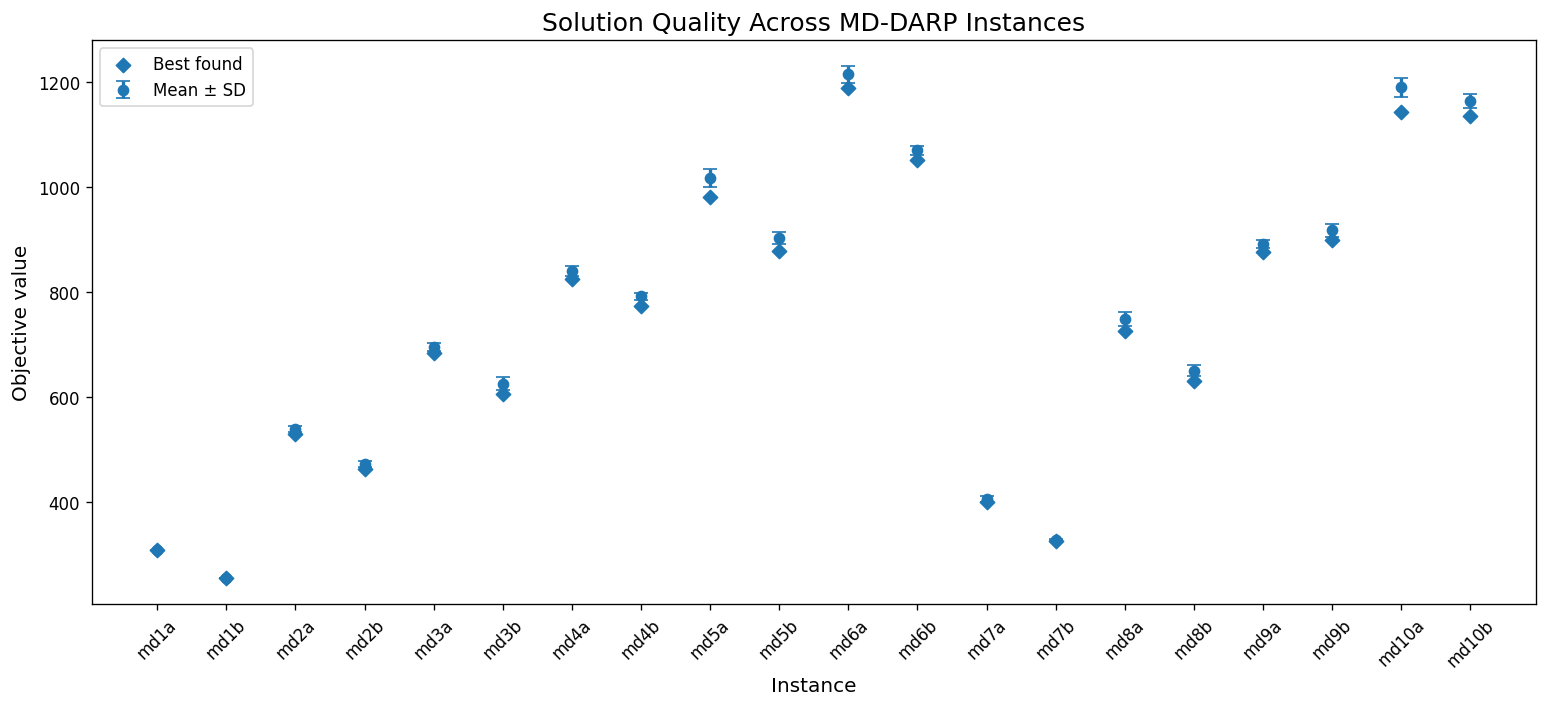

In [11]:
# ---------------------------------------------------------
# Objective by instance
# ---------------------------------------------------------

plot_df = instance_summary.sort_values(["size_id", "regime"]).copy()

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(plot_df))

ax.errorbar(
    x,
    plot_df["mean_objective"],
    yerr=plot_df["std_objective"],
    fmt="o",
    capsize=4,
    label="Mean ± SD"
)

ax.scatter(
    x,
    plot_df["best_objective"],
    marker="D",
    label="Best found"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["instance"], rotation=45)
ax.set_xlabel("Instance")
ax.set_ylabel("Objective value")
ax.set_title("Solution Quality Across MD-DARP Instances")
ax.legend()

plt.tight_layout()
plt.show()


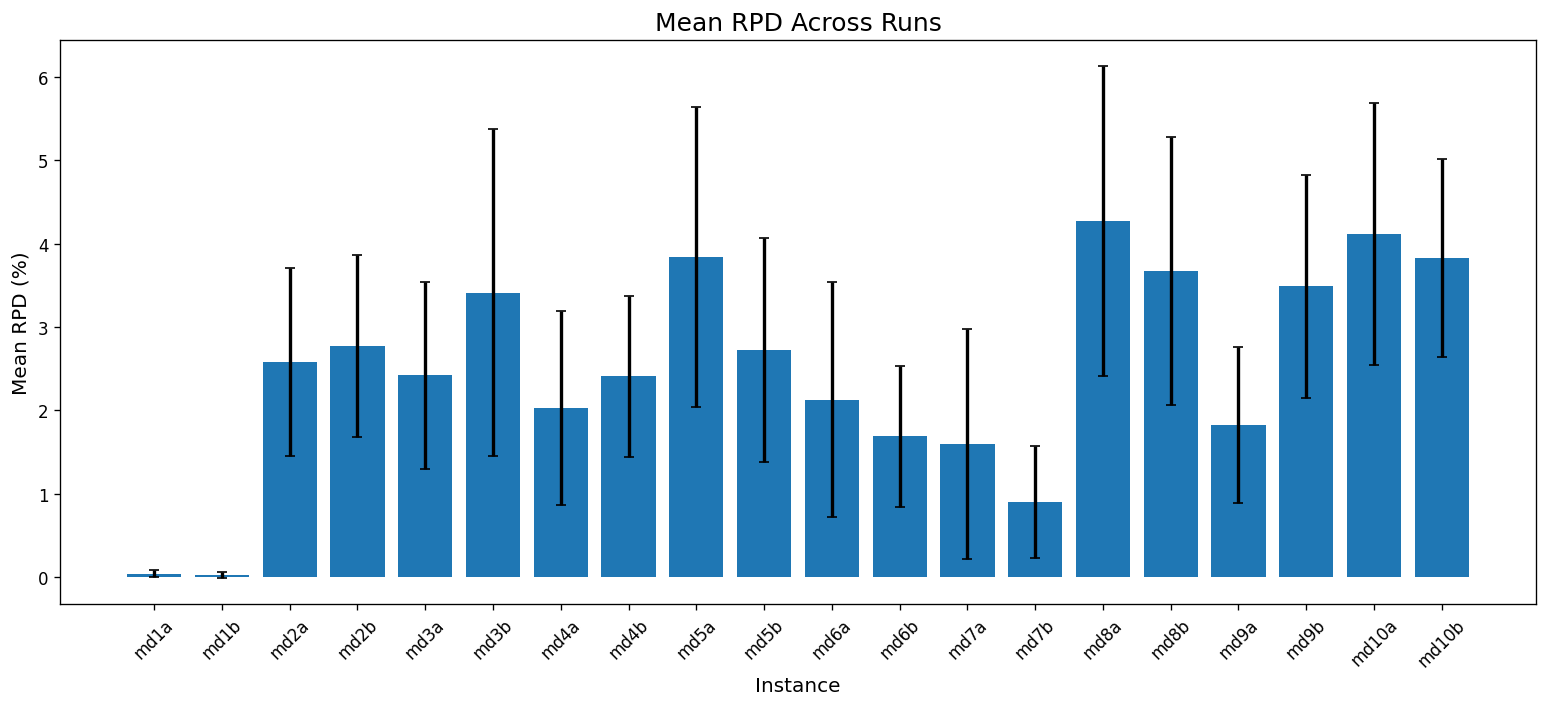

In [12]:
# ---------------------------------------------------------
# Mean RPD by instance
# ---------------------------------------------------------

plot_df = instance_rpd_summary.sort_values(["size_id", "regime"]).copy()

fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    plot_df["instance"],
    plot_df["mean_RPD"],
    yerr=plot_df["std_RPD"],
    capsize=3
)

ax.set_xlabel("Instance")
ax.set_ylabel("Mean RPD (%)")
ax.set_title("Mean RPD Across Runs")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 9. Runtime and scalability

These figures examine how computational effort changes with the number of requests.

The scatter plot uses all 400 runs; the second figure uses instance-level mean runtime.


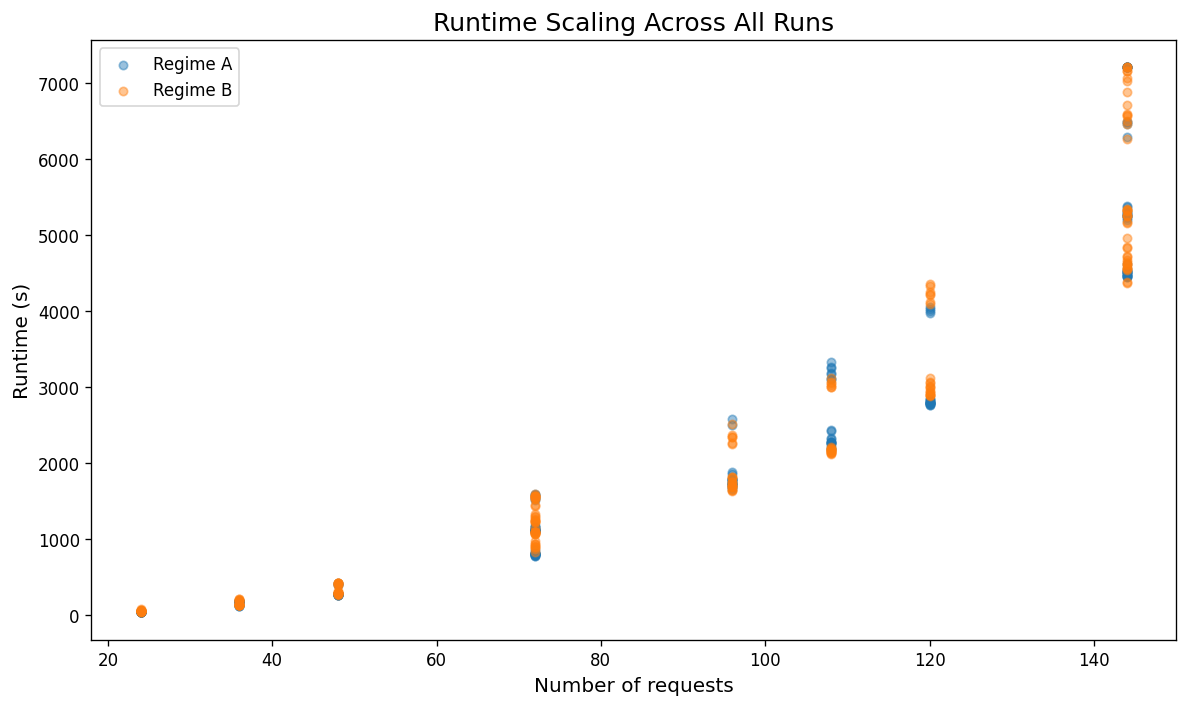

In [13]:
# ---------------------------------------------------------
# Runtime vs. number of requests: all runs
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

for regime, g in df_runs.groupby(
    df_runs["instance"].str[-1].str.upper()
):
    ax.scatter(
        g["num_requests"],
        g["elapsed_time_sec"],
        alpha=0.45,
        s=25,
        label=f"Regime {regime}"
    )

ax.set_xlabel("Number of requests")
ax.set_ylabel("Runtime (s)")
ax.set_title("Runtime Scaling Across All Runs")
ax.legend()

plt.tight_layout()
plt.show()


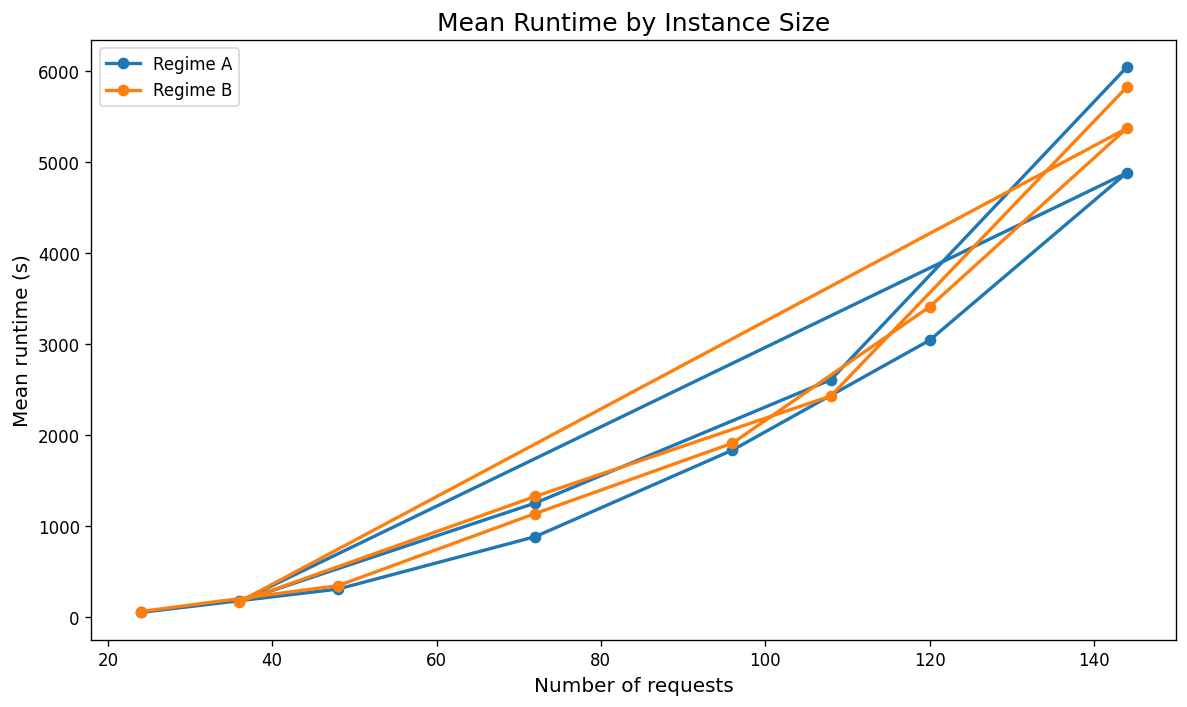

In [14]:
# ---------------------------------------------------------
# Instance-level mean runtime
# ---------------------------------------------------------

plot_df = instance_summary.sort_values("size_id")

fig, ax = plt.subplots(figsize=(10, 6))

for regime, g in plot_df.groupby("regime"):
    ax.plot(
        g["n_requests"],
        g["mean_runtime_sec"],
        marker="o",
        label=f"Regime {regime}"
    )

ax.set_xlabel("Number of requests")
ax.set_ylabel("Mean runtime (s)")
ax.set_title("Mean Runtime by Instance Size")
ax.legend()

plt.tight_layout()
plt.show()


## 10. Tight vs. loose time-window regimes

The generated instances use:

- `a`: tighter time windows
- `b`: looser time windows

The following tables and figures compare the two regimes.


In [15]:
# ---------------------------------------------------------
# Regime comparison
# ---------------------------------------------------------

regime_summary = (
    df_runs
    .assign(regime=df_runs["instance"].str[-1].str.upper())
    .groupby("regime")
    .agg(
        runs=("run_id", "count"),
        instances=("instance", "nunique"),
        mean_RPD=("RPD_percent", "mean"),
        median_RPD=("RPD_percent", "median"),
        mean_runtime_sec=("elapsed_time_sec", "mean"),
        median_runtime_sec=("elapsed_time_sec", "median"),
        mean_objective=("best_feasible_objective", "mean"),
    )
    .reset_index()
)

display(regime_summary.round(4))


,regime,runs,instances,mean_RPD,median_RPD,mean_runtime_sec,median_runtime_sec,mean_objective
0,A,200,10,2.4839,2.3064,2106.0108,1627.680,785.1557
1,B,200,10,2.4905,2.5012,2196.6944,1611.335,717.9387


/tmp/ipykernel_30505/3933957553.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(rpd_values, labels=regime_order)
/tmp/ipykernel_30505/3933957553.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(runtime_values, labels=regime_order)


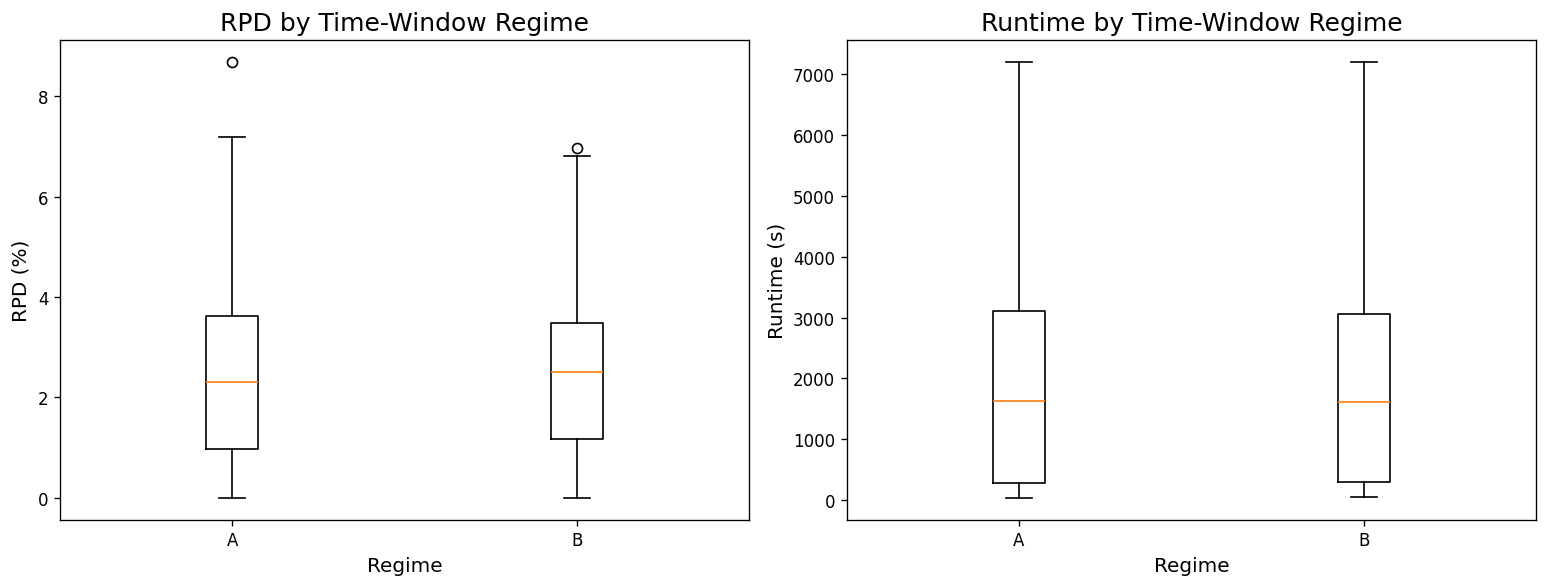

In [16]:
# ---------------------------------------------------------
# Regime comparison: RPD and runtime
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

regime_order = ["A", "B"]
rpd_values = [
    df_runs.loc[df_runs["instance"].str[-1].str.upper() == r, "RPD_percent"].dropna()
    for r in regime_order
]
runtime_values = [
    df_runs.loc[df_runs["instance"].str[-1].str.upper() == r, "elapsed_time_sec"].dropna()
    for r in regime_order
]

axes[0].boxplot(rpd_values, labels=regime_order)
axes[0].set_title("RPD by Time-Window Regime")
axes[0].set_xlabel("Regime")
axes[0].set_ylabel("RPD (%)")

axes[1].boxplot(runtime_values, labels=regime_order)
axes[1].set_title("Runtime by Time-Window Regime")
axes[1].set_xlabel("Regime")
axes[1].set_ylabel("Runtime (s)")

plt.tight_layout()
plt.show()


## 11. Operator selection frequencies

For the adaptive ALNS, operator selection is analyzed from the convergence logs.

**Important:** these are selection frequencies, not performance scores.

Because the reward is collective for the selected destroy-repair pair, it is analyzed separately below.


In [17]:
# ---------------------------------------------------------
# Operator selection: per-run statistics first
# ---------------------------------------------------------

valid_operator_rows = df_conv_all[
    df_conv_all["destroy_op"].isin(DESTROY_METHODS.keys())
    & df_conv_all["repair_op"].isin(REPAIR_METHODS.keys())
].copy()

# Selection frequencies within each run.
destroy_run_freq = (
    valid_operator_rows
    .groupby(["run_id", "instance", "seed", "destroy_op"])
    .size()
    .rename("selections")
    .reset_index()
)

destroy_run_totals = (
    valid_operator_rows
    .groupby("run_id")
    .size()
    .rename("total_operator_selections")
)

destroy_run_freq["selection_pct"] = (
    100
    * destroy_run_freq["selections"]
    / destroy_run_freq["run_id"].map(destroy_run_totals)
)

destroy_run_freq["operator"] = destroy_run_freq["destroy_op"].map(DESTROY_METHODS)

destroy_selection_summary = (
    destroy_run_freq
    .groupby("operator")
    .agg(
        mean_selection_pct=("selection_pct", "mean"),
        median_selection_pct=("selection_pct", "median"),
        std_selection_pct=("selection_pct", "std"),
        runs=("selection_pct", "count"),
    )
    .reset_index()
    .sort_values("mean_selection_pct", ascending=False)
)

# Repair frequencies
repair_run_freq = (
    valid_operator_rows
    .groupby(["run_id", "instance", "seed", "repair_op"])
    .size()
    .rename("selections")
    .reset_index()
)

repair_run_freq["selection_pct"] = (
    100
    * repair_run_freq["selections"]
    / repair_run_freq["run_id"].map(destroy_run_totals)
)

repair_run_freq["operator"] = repair_run_freq["repair_op"].map(REPAIR_METHODS)

repair_selection_summary = (
    repair_run_freq
    .groupby("operator")
    .agg(
        mean_selection_pct=("selection_pct", "mean"),
        median_selection_pct=("selection_pct", "median"),
        std_selection_pct=("selection_pct", "std"),
        runs=("selection_pct", "count"),
    )
    .reset_index()
    .sort_values("mean_selection_pct", ascending=False)
)

print("Destroy operator selection")
display(destroy_selection_summary.round(3))

print("Repair operator selection")
display(repair_selection_summary.round(3))


Destroy operator selection


,operator,mean_selection_pct,median_selection_pct,std_selection_pct,runs
0,Random,34.757,34.715,1.504,400
2,Worst,34.325,34.605,2.378,400
1,Shaw,30.918,30.295,2.890,400


Repair operator selection


,operator,mean_selection_pct,median_selection_pct,std_selection_pct,runs
1,Regret-2,40.404,41.130,4.188,400
2,Regret-3,38.726,38.785,3.791,400
0,Greedy,20.870,19.880,7.644,400


In [18]:
# ---------------------------------------------------------
# Compact operator-selection table
# ---------------------------------------------------------

operator_selection_table = pd.concat([
    destroy_selection_summary.assign(type="Destroy"),
    repair_selection_summary.assign(type="Repair"),
], ignore_index=True)

operator_selection_table = operator_selection_table[
    [
        "type", "operator",
        "mean_selection_pct",
        "median_selection_pct",
        "std_selection_pct"
    ]
]

display(operator_selection_table.round(3))


,type,operator,mean_selection_pct,median_selection_pct,std_selection_pct
0,Destroy,Random,34.757,34.715,1.504
1,Destroy,Worst,34.325,34.605,2.378
2,Destroy,Shaw,30.918,30.295,2.890
3,Repair,Regret-2,40.404,41.130,4.188
4,Repair,Regret-3,38.726,38.785,3.791
5,Repair,Greedy,20.870,19.880,7.644


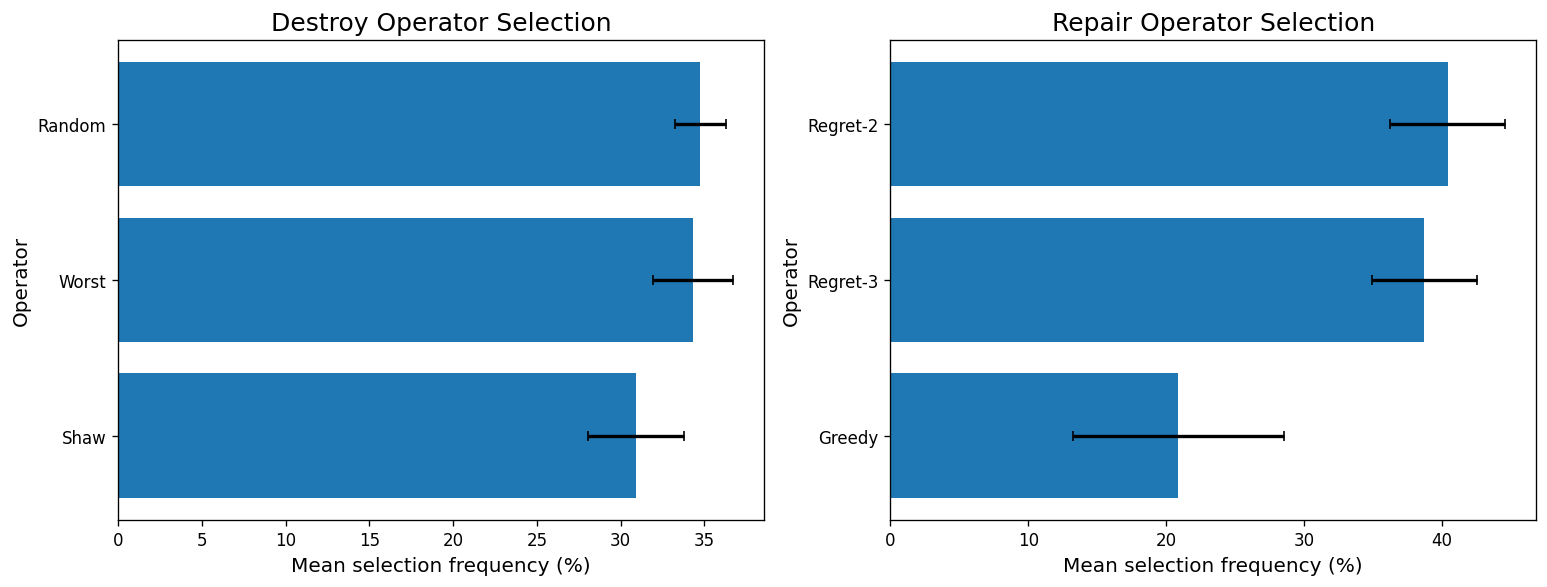

In [19]:
# ---------------------------------------------------------
# Operator selection plots
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

d = destroy_selection_summary.sort_values("mean_selection_pct")
axes[0].barh(
    d["operator"],
    d["mean_selection_pct"],
    xerr=d["std_selection_pct"],
    capsize=3
)
axes[0].set_title("Destroy Operator Selection")
axes[0].set_xlabel("Mean selection frequency (%)")
axes[0].set_ylabel("Operator")

r = repair_selection_summary.sort_values("mean_selection_pct")
axes[1].barh(
    r["operator"],
    r["mean_selection_pct"],
    xerr=r["std_selection_pct"],
    capsize=3
)
axes[1].set_title("Repair Operator Selection")
axes[1].set_xlabel("Mean selection frequency (%)")
axes[1].set_ylabel("Operator")

plt.tight_layout()
plt.show()


## 12. Destroy-repair pair selection

Since the reward belongs to the selected **destroy-repair pair**, the pair is the correct unit for reward analysis.


In [20]:
# ---------------------------------------------------------
# Pair selection frequencies
# ---------------------------------------------------------

pair_run_freq = (
    valid_operator_rows
    .groupby([
        "run_id", "instance", "seed",
        "destroy_op", "repair_op"
    ])
    .size()
    .rename("selections")
    .reset_index()
)

pair_run_freq["selection_pct"] = (
    100
    * pair_run_freq["selections"]
    / pair_run_freq["run_id"].map(destroy_run_totals)
)

pair_run_freq["destroy"] = pair_run_freq["destroy_op"].map(DESTROY_METHODS)
pair_run_freq["repair"] = pair_run_freq["repair_op"].map(REPAIR_METHODS)
pair_run_freq["pair"] = pair_run_freq["destroy"] + " + " + pair_run_freq["repair"]

pair_selection_summary = (
    pair_run_freq
    .groupby("pair")
    .agg(
        mean_selection_pct=("selection_pct", "mean"),
        median_selection_pct=("selection_pct", "median"),
        std_selection_pct=("selection_pct", "std"),
        runs_with_pair=("selection_pct", "count"),
    )
    .reset_index()
    .sort_values("mean_selection_pct", ascending=False)
)

display(pair_selection_summary.round(3))


,pair,mean_selection_pct,median_selection_pct,std_selection_pct,runs_with_pair
1,Random + Regret-2,14.125,14.415,1.714,400
7,Worst + Regret-2,13.984,14.385,2.181,400
2,Random + Regret-3,13.461,13.735,1.493,400
8,Worst + Regret-3,13.357,13.665,1.934,400
4,Shaw + Regret-2,12.295,12.210,1.090,400
5,Shaw + Regret-3,11.908,11.770,1.165,400
0,Random + Greedy,7.170,6.940,2.584,400
6,Worst + Greedy,6.984,7.035,2.282,400
3,Shaw + Greedy,6.715,6.035,2.917,400


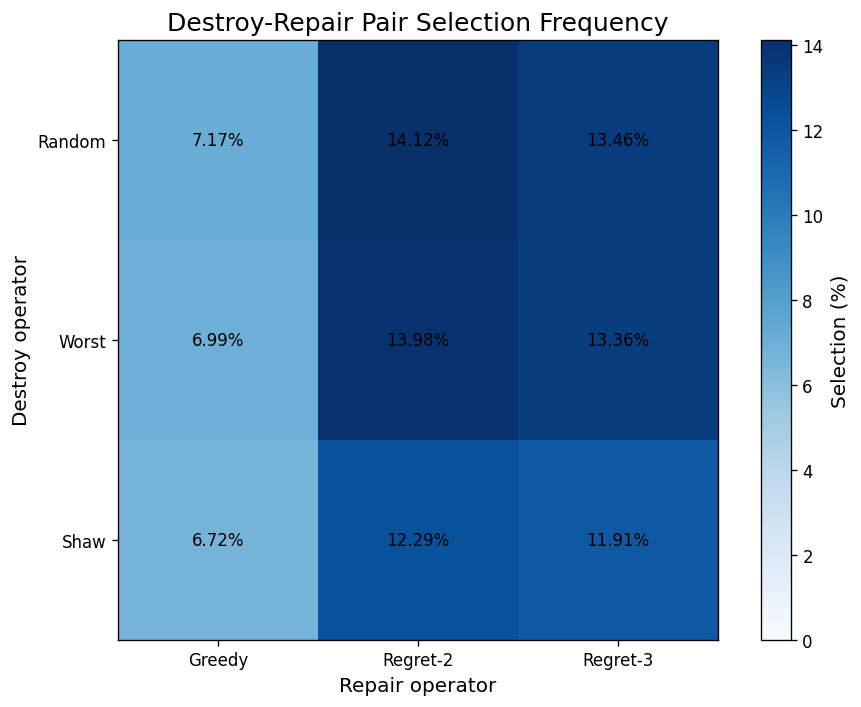

In [21]:
# ---------------------------------------------------------
# Pair selection heatmap
# ---------------------------------------------------------

pair_matrix = (
    valid_operator_rows
    .groupby(["destroy_op", "repair_op"])
    .size()
    .unstack(fill_value=0)
)

# Convert pooled counts to percentages for a compact exploratory view.
pair_matrix_pct = 100 * pair_matrix / pair_matrix.values.sum()

pair_matrix_named = pair_matrix_pct.rename(
    index=DESTROY_METHODS,
    columns=REPAIR_METHODS
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    pair_matrix_named.values,
    cmap="Blues",
    vmin=0,
    vmax=pair_matrix_named.values.max()
)

ax.set_xticks(range(len(pair_matrix_named.columns)))
ax.set_xticklabels(pair_matrix_named.columns)
ax.set_yticks(range(len(pair_matrix_named.index)))
ax.set_yticklabels(pair_matrix_named.index)

for i in range(pair_matrix_named.shape[0]):
    for j in range(pair_matrix_named.shape[1]):
        ax.text(
            j, i,
            f"{pair_matrix_named.iloc[i, j]:.2f}%",
            ha="center",
            va="center"
        )

ax.set_xlabel("Repair operator")
ax.set_ylabel("Destroy operator")
ax.set_title("Destroy-Repair Pair Selection Frequency")

fig.colorbar(im, ax=ax, label="Selection (%)")

plt.tight_layout()
plt.show()


## 13. Collective reward analysis

The `reward` column is **collective** for the selected destroy-repair pair.

Therefore, the tables below report:

- mean reward of a pair when selected;
- median reward;
- fraction of selections receiving positive reward.

They do **not** claim that the reward belongs independently to the destroy or repair operator.


In [22]:
# ---------------------------------------------------------
# Pair-level collective reward
# ---------------------------------------------------------

pair_reward = (
    valid_operator_rows
    .groupby(["destroy_op", "repair_op"])
    .agg(
        selections=("reward", "size"),
        mean_reward=("reward", "mean"),
        median_reward=("reward", "median"),
        std_reward=("reward", "std"),
        positive_reward_pct=("reward", lambda x: 100 * (x > 0).mean()),
        zero_reward_pct=("reward", lambda x: 100 * (x == 0).mean()),
    )
    .reset_index()
)

pair_reward["destroy"] = pair_reward["destroy_op"].map(DESTROY_METHODS)
pair_reward["repair"] = pair_reward["repair_op"].map(REPAIR_METHODS)
pair_reward["pair"] = pair_reward["destroy"] + " + " + pair_reward["repair"]

pair_reward = pair_reward[
    [
        "pair", "selections",
        "mean_reward", "median_reward", "std_reward",
        "positive_reward_pct", "zero_reward_pct"
    ]
].sort_values("mean_reward", ascending=False)

display(pair_reward.round(4))


,pair,selections,mean_reward,median_reward,std_reward,positive_reward_pct,zero_reward_pct
5,Worst + Regret-3,534048,9.4776,0.0,10.5548,44.7851,55.2149
4,Worst + Regret-2,559146,9.2531,0.0,10.5112,43.8247,56.1753
2,Random + Regret-3,538242,9.0748,0.0,10.6334,42.2330,57.7670
8,Shaw + Regret-3,476130,9.0394,0.0,10.6210,42.1003,57.8997
1,Random + Regret-2,564787,8.9362,0.0,10.5770,41.7570,58.2430
7,Shaw + Regret-2,491593,8.7290,0.0,10.5517,40.7284,59.2716
0,Random + Greedy,286766,6.0724,0.0,9.7667,27.9210,72.0790
6,Shaw + Greedy,268570,5.9699,0.0,9.7294,27.3873,72.6127
3,Worst + Greedy,279320,5.8883,0.0,9.6244,27.2956,72.7044


/tmp/ipykernel_30505/4002194158.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(reward_data, labels=pairs, showfliers=False)


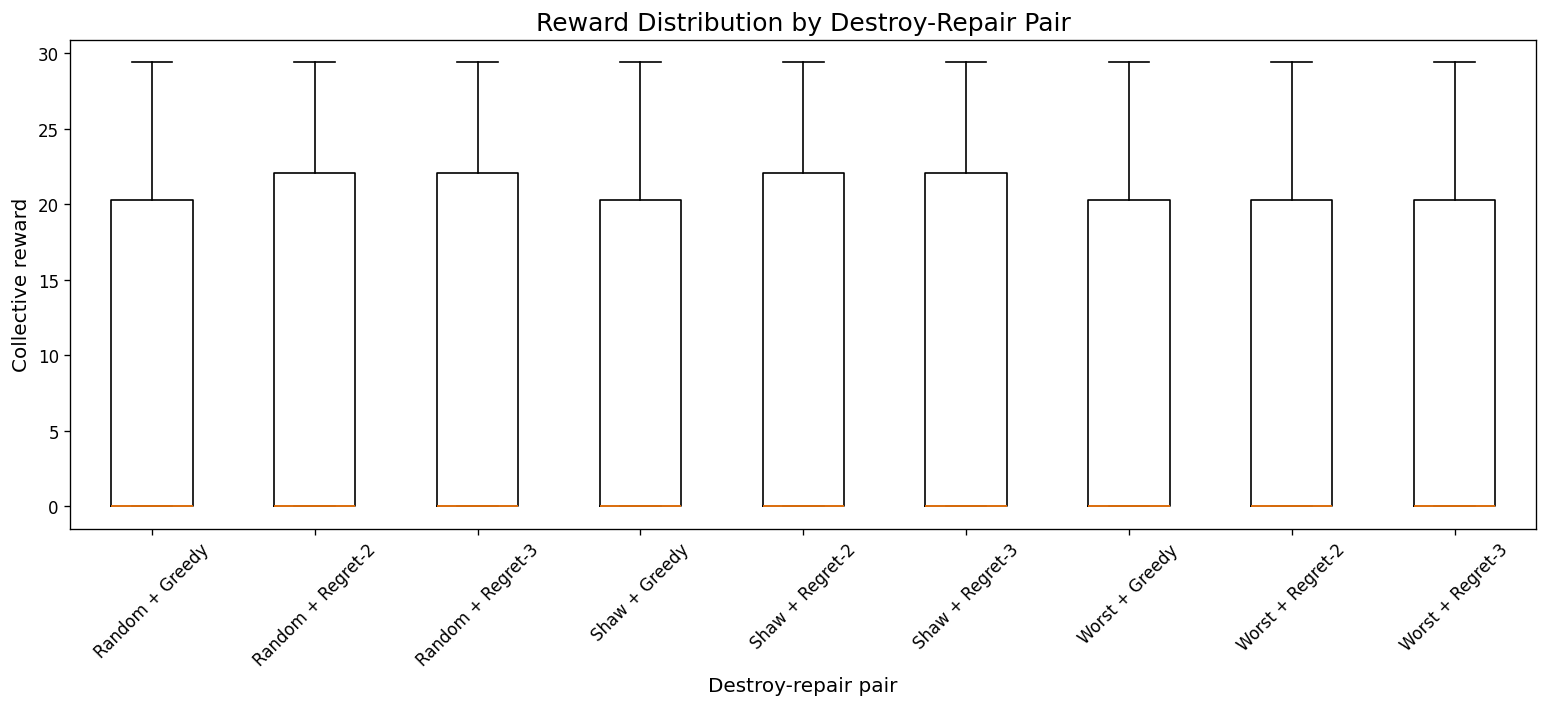

In [23]:
# ---------------------------------------------------------
# Reward distribution by destroy-repair pair
# ---------------------------------------------------------

reward_plot_df = valid_operator_rows.copy()
reward_plot_df["destroy"] = reward_plot_df["destroy_op"].map(DESTROY_METHODS)
reward_plot_df["repair"] = reward_plot_df["repair_op"].map(REPAIR_METHODS)
reward_plot_df["pair"] = reward_plot_df["destroy"] + " + " + reward_plot_df["repair"]

pairs = sorted(reward_plot_df["pair"].dropna().unique())
reward_data = [
    reward_plot_df.loc[reward_plot_df["pair"] == p, "reward"].dropna()
    for p in pairs
]

fig, ax = plt.subplots(figsize=(13, 6))

ax.boxplot(reward_data, labels=pairs, showfliers=False)

ax.set_xlabel("Destroy-repair pair")
ax.set_ylabel("Collective reward")
ax.set_title("Reward Distribution by Destroy-Repair Pair")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 14. Operator behaviour by time-window regime

This is useful for the paper because the benchmark was explicitly generated with tight (`a`) and loose (`b`) time-window regimes.

The comparison is based on **per-run selection frequencies**, avoiding overweighting runs with more log rows.


In [24]:
# ---------------------------------------------------------
# Operator selection by regime
# ---------------------------------------------------------

destroy_run_freq["regime"] = destroy_run_freq["instance"].str[-1].str.upper()
repair_run_freq["regime"] = repair_run_freq["instance"].str[-1].str.upper()

destroy_regime_summary = (
    destroy_run_freq
    .groupby(["regime", "operator"])
    .agg(
        mean_selection_pct=("selection_pct", "mean"),
        std_selection_pct=("selection_pct", "std"),
    )
    .reset_index()
)

repair_regime_summary = (
    repair_run_freq
    .groupby(["regime", "operator"])
    .agg(
        mean_selection_pct=("selection_pct", "mean"),
        std_selection_pct=("selection_pct", "std"),
    )
    .reset_index()
)

print("Destroy operators by regime")
display(destroy_regime_summary.round(3))

print("Repair operators by regime")
display(repair_regime_summary.round(3))


Destroy operators by regime


,regime,operator,mean_selection_pct,std_selection_pct
0,A,Random,34.813,1.460
1,A,Shaw,31.097,3.058
2,A,Worst,34.090,2.355
3,B,Random,34.700,1.548
4,B,Shaw,30.740,2.708
5,B,Worst,34.560,2.383


Repair operators by regime


,regime,operator,mean_selection_pct,std_selection_pct
0,A,Greedy,20.203,7.280
1,A,Regret-2,41.036,3.997
2,A,Regret-3,38.762,3.621
3,B,Greedy,21.537,7.953
4,B,Regret-2,39.772,4.288
5,B,Regret-3,38.691,3.964


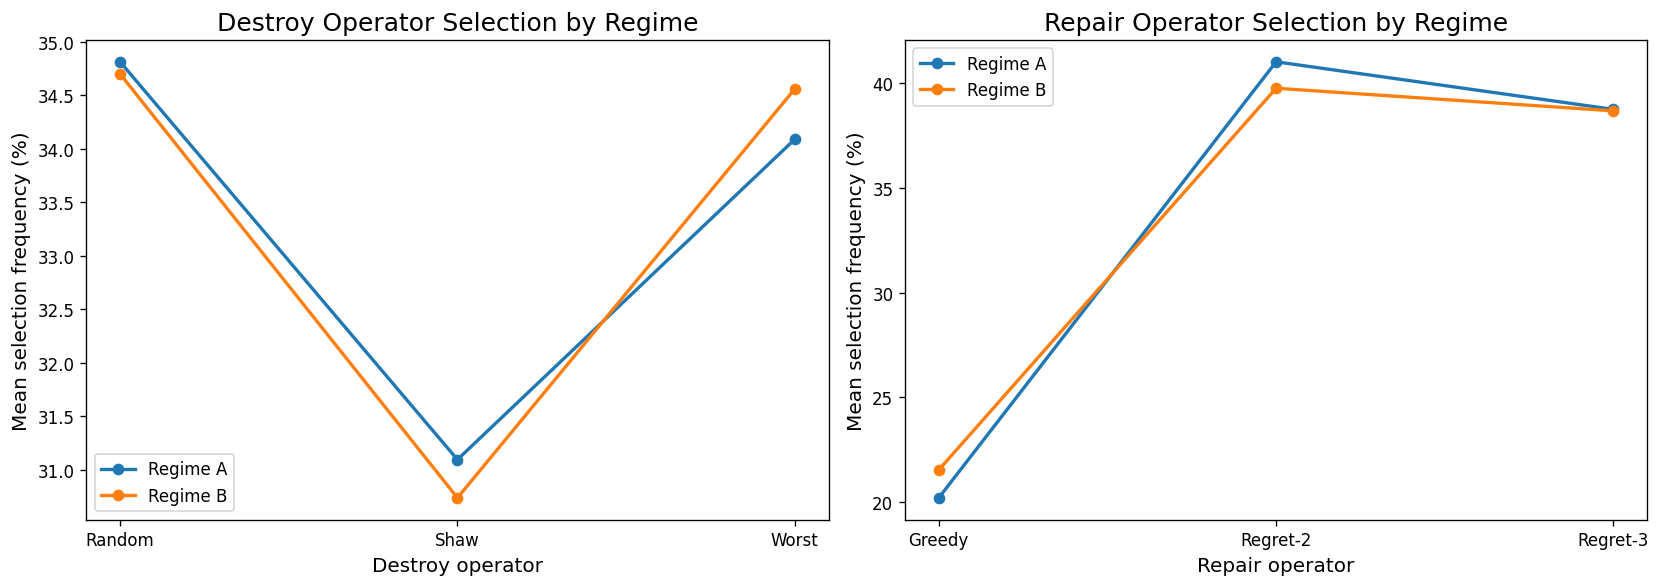

In [25]:
# ---------------------------------------------------------
# Regime-specific operator selection plots
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for regime in ["A", "B"]:
    d = destroy_regime_summary[
        destroy_regime_summary["regime"] == regime
    ].sort_values("operator")

    axes[0].plot(
        d["operator"],
        d["mean_selection_pct"],
        marker="o",
        label=f"Regime {regime}"
    )

    r = repair_regime_summary[
        repair_regime_summary["regime"] == regime
    ].sort_values("operator")

    axes[1].plot(
        r["operator"],
        r["mean_selection_pct"],
        marker="o",
        label=f"Regime {regime}"
    )

axes[0].set_title("Destroy Operator Selection by Regime")
axes[0].set_xlabel("Destroy operator")
axes[0].set_ylabel("Mean selection frequency (%)")
axes[0].legend()

axes[1].set_title("Repair Operator Selection by Regime")
axes[1].set_xlabel("Repair operator")
axes[1].set_ylabel("Mean selection frequency (%)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 15. Operator behaviour by instance size

The instance naming convention gives a natural size index from `md1` to `md10`.

This section checks whether operator preferences change as the number of requests increases.


In [26]:
# ---------------------------------------------------------
# Add size index to operator-frequency data
# ---------------------------------------------------------

destroy_run_freq["size_id"] = (
    destroy_run_freq["instance"]
    .str.extract(r"md(\d+)[ab]", expand=False)
    .astype(int)
)

repair_run_freq["size_id"] = (
    repair_run_freq["instance"]
    .str.extract(r"md(\d+)[ab]", expand=False)
    .astype(int)
)

destroy_size_summary = (
    destroy_run_freq
    .groupby(["size_id", "operator"])
    ["selection_pct"]
    .mean()
    .reset_index()
)

repair_size_summary = (
    repair_run_freq
    .groupby(["size_id", "operator"])
    ["selection_pct"]
    .mean()
    .reset_index()
)

display(destroy_size_summary.round(3).head(10))
display(repair_size_summary.round(3).head(10))


,size_id,operator,selection_pct
0,1,Random,32.844
1,1,Shaw,36.060
2,1,Worst,31.096
3,2,Random,35.006
4,2,Shaw,31.517
5,2,Worst,33.476
6,3,Random,35.485
7,3,Shaw,30.399
8,3,Worst,34.116
9,4,Random,35.432


,size_id,operator,selection_pct
0,1,Greedy,35.850
1,1,Regret-2,31.826
2,1,Regret-3,32.324
3,2,Greedy,25.238
4,2,Regret-2,38.374
5,2,Regret-3,36.388
6,3,Greedy,23.030
7,3,Regret-2,39.315
8,3,Regret-3,37.654
9,4,Greedy,21.478


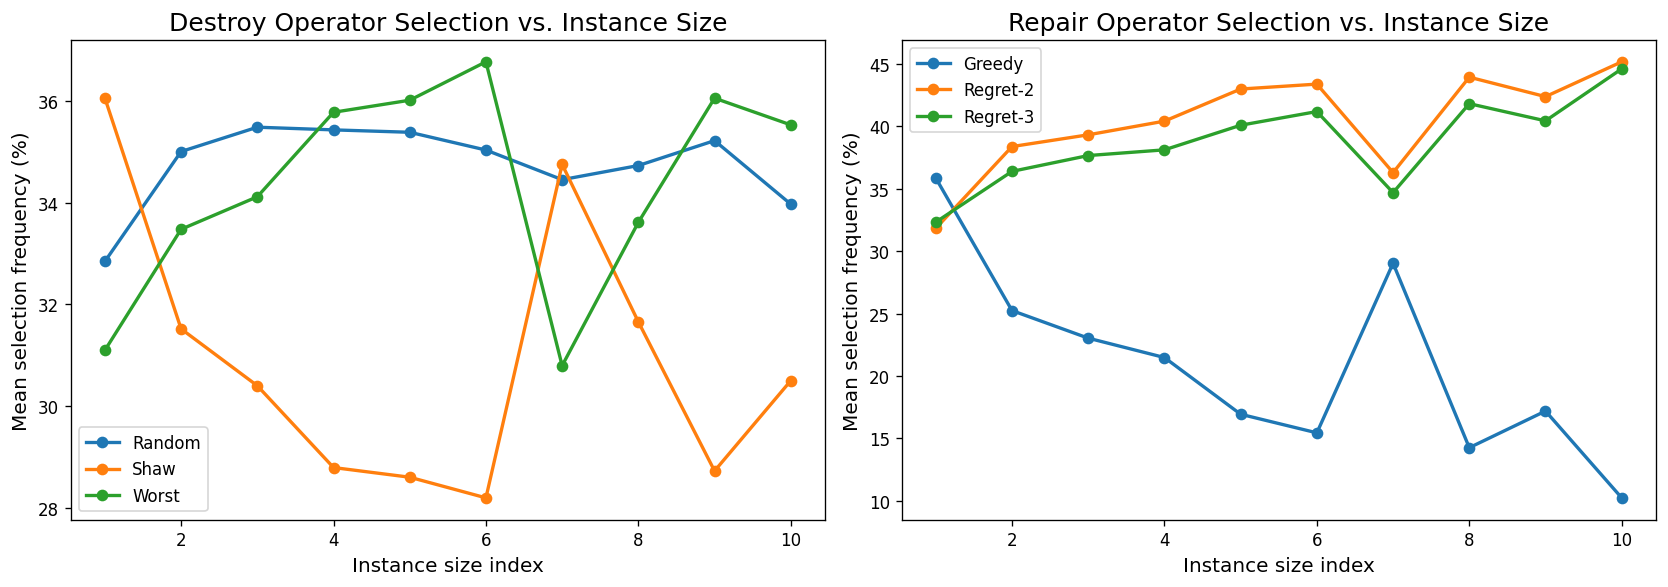

In [27]:
# ---------------------------------------------------------
# Operator selection as instance size increases
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for operator, g in destroy_size_summary.groupby("operator"):
    axes[0].plot(
        g["size_id"],
        g["selection_pct"],
        marker="o",
        label=operator
    )

for operator, g in repair_size_summary.groupby("operator"):
    axes[1].plot(
        g["size_id"],
        g["selection_pct"],
        marker="o",
        label=operator
    )

axes[0].set_title("Destroy Operator Selection vs. Instance Size")
axes[0].set_xlabel("Instance size index")
axes[0].set_ylabel("Mean selection frequency (%)")
axes[0].legend()

axes[1].set_title("Repair Operator Selection vs. Instance Size")
axes[1].set_xlabel("Instance size index")
axes[1].set_ylabel("Mean selection frequency (%)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 16. Adaptive weight evolution

The weight logs show what the adaptive mechanism learns at the segment level.

For individual instances, the next section plots the exact trajectory. For the aggregate analysis, the weights are summarized by relative search progress because runs can contain different numbers of segments.


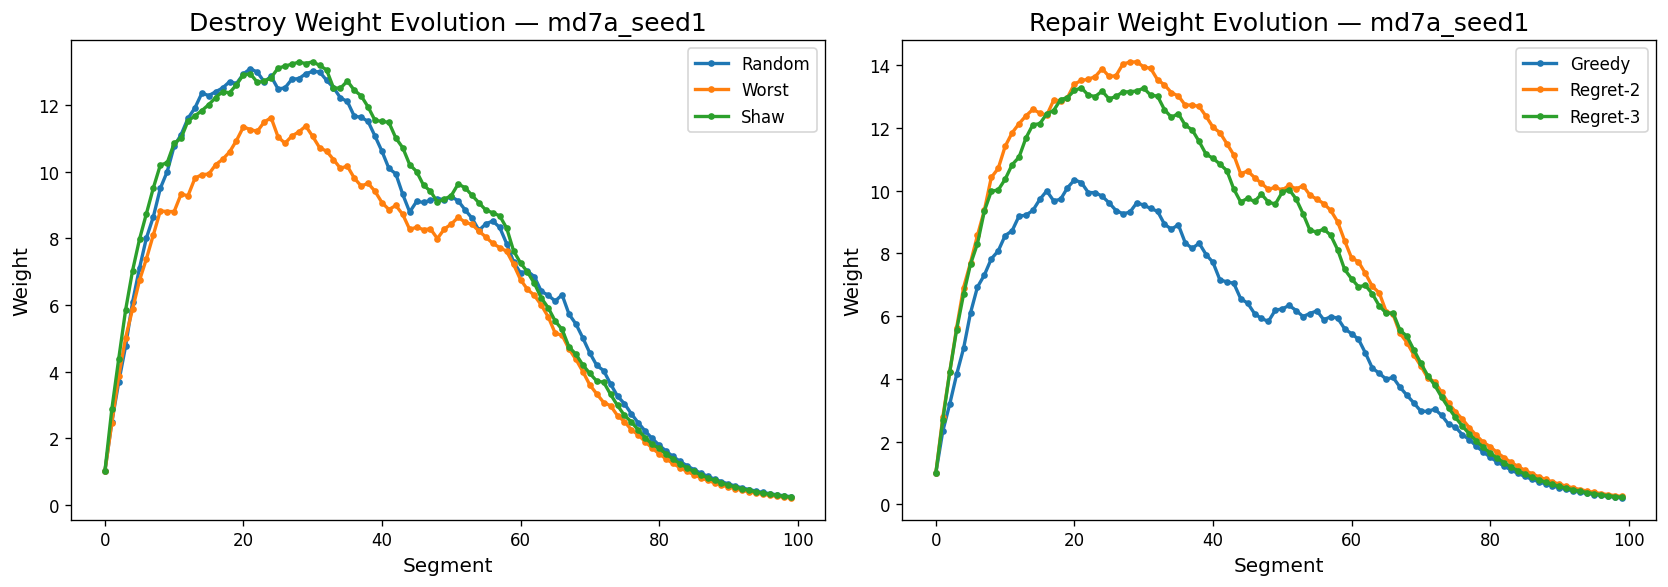

In [28]:
# ---------------------------------------------------------
# Individual weight evolution helper
# ---------------------------------------------------------

def plot_weights_for_run(instance, seed):
    if df_weights_all.empty:
        print("No weight logs were loaded.")
        return

    run_id = f"{instance}_seed{seed}"
    g = df_weights_all[df_weights_all["run_id"] == run_id].sort_values("segment")

    if g.empty:
        print(f"No weight log found for {run_id}.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    destroy_cols = [
        "destroy_weight_0",
        "destroy_weight_1",
        "destroy_weight_2",
    ]
    repair_cols = [
        "repair_weight_0",
        "repair_weight_1",
        "repair_weight_2",
    ]

    for i, col in enumerate(destroy_cols):
        axes[0].plot(
            g["segment"],
            g[col],
            marker="o",
            markersize=3,
            label=DESTROY_METHODS[i]
        )

    for i, col in enumerate(repair_cols):
        axes[1].plot(
            g["segment"],
            g[col],
            marker="o",
            markersize=3,
            label=REPAIR_METHODS[i]
        )

    axes[0].set_title(f"Destroy Weight Evolution — {run_id}")
    axes[0].set_xlabel("Segment")
    axes[0].set_ylabel("Weight")
    axes[0].legend()

    axes[1].set_title(f"Repair Weight Evolution — {run_id}")
    axes[1].set_xlabel("Segment")
    axes[1].set_ylabel("Weight")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_weights_for_run("md7a", 1)


## 17. Individual-instance convergence analysis

Use this section to inspect a representative instance in detail.

Change `SELECTED_INSTANCE` and `SELECTED_SEED` below.


In [29]:
# ---------------------------------------------------------
# Select an individual run
# ---------------------------------------------------------

SELECTED_INSTANCE = "md5a"
SELECTED_SEED = 1

selected_run_id = f"{SELECTED_INSTANCE}_seed{SELECTED_SEED}"

df_selected = (
    df_conv_all[df_conv_all["run_id"] == selected_run_id]
    .sort_values("iteration")
    .copy()
)

if df_selected.empty:
    print(f"No convergence log found for {selected_run_id}.")
else:
    print(f"Selected run: {selected_run_id}")
    print(f"Iterations: {len(df_selected):,}")
    print(f"Runtime: {df_selected['elapsed_time'].max():.3f} s")
    print(f"Best objective: {df_selected['best_obj'].min():.6f}")

    feasible = df_selected["best_feasible_obj"].dropna()
    if not feasible.empty:
        print(f"Best feasible objective: {feasible.min():.6f}")


Selected run: md5a_seed1
Iterations: 10,000
Runtime: 2788.650 s
Best objective: 1026.580000
Best feasible objective: 1026.580000


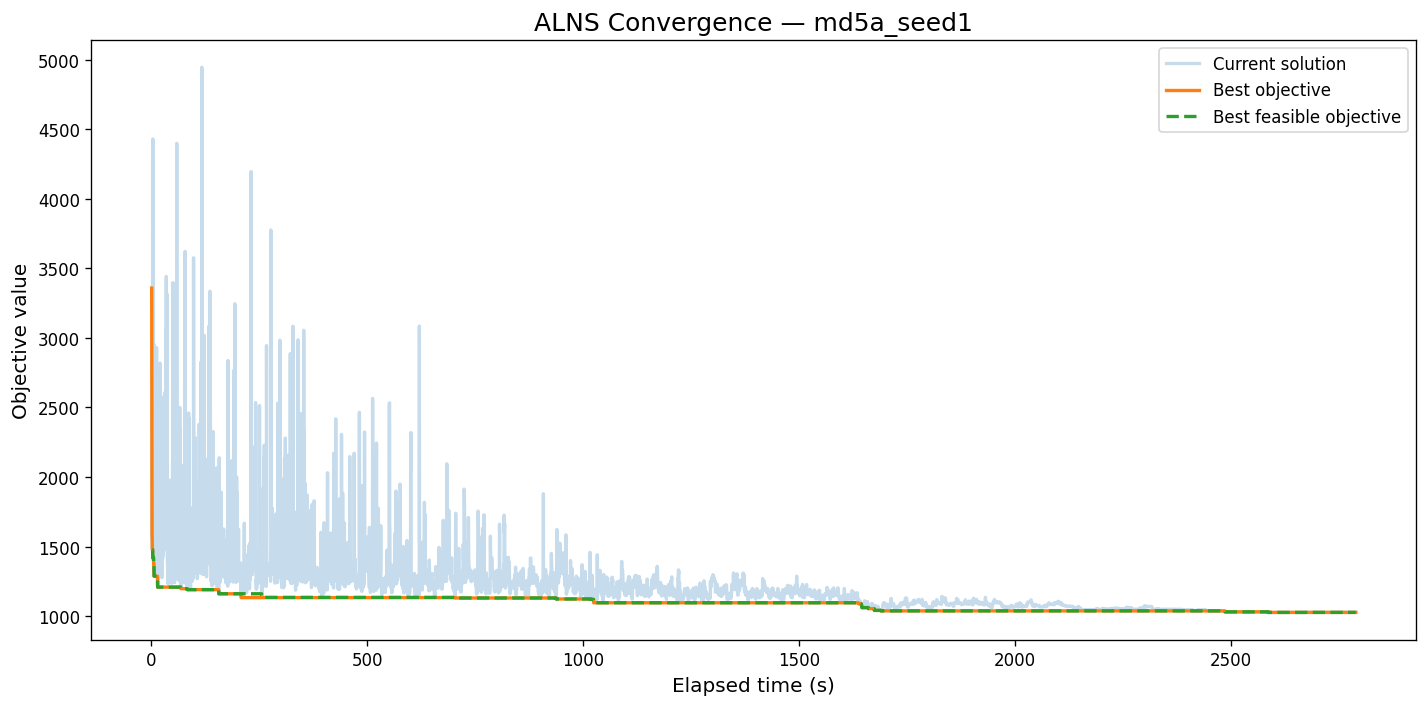

In [30]:
# ---------------------------------------------------------
# Individual convergence
# ---------------------------------------------------------

if not df_selected.empty:
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(
        df_selected["elapsed_time"],
        df_selected["current_obj"],
        alpha=0.25,
        label="Current solution"
    )

    ax.plot(
        df_selected["elapsed_time"],
        df_selected["best_obj"],
        label="Best objective"
    )

    ax.plot(
        df_selected["elapsed_time"],
        df_selected["best_feasible_obj"],
        linestyle="--",
        label="Best feasible objective"
    )

    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel("Objective value")
    ax.set_title(f"ALNS Convergence — {selected_run_id}")
    ax.legend()

    plt.tight_layout()
    plt.show()


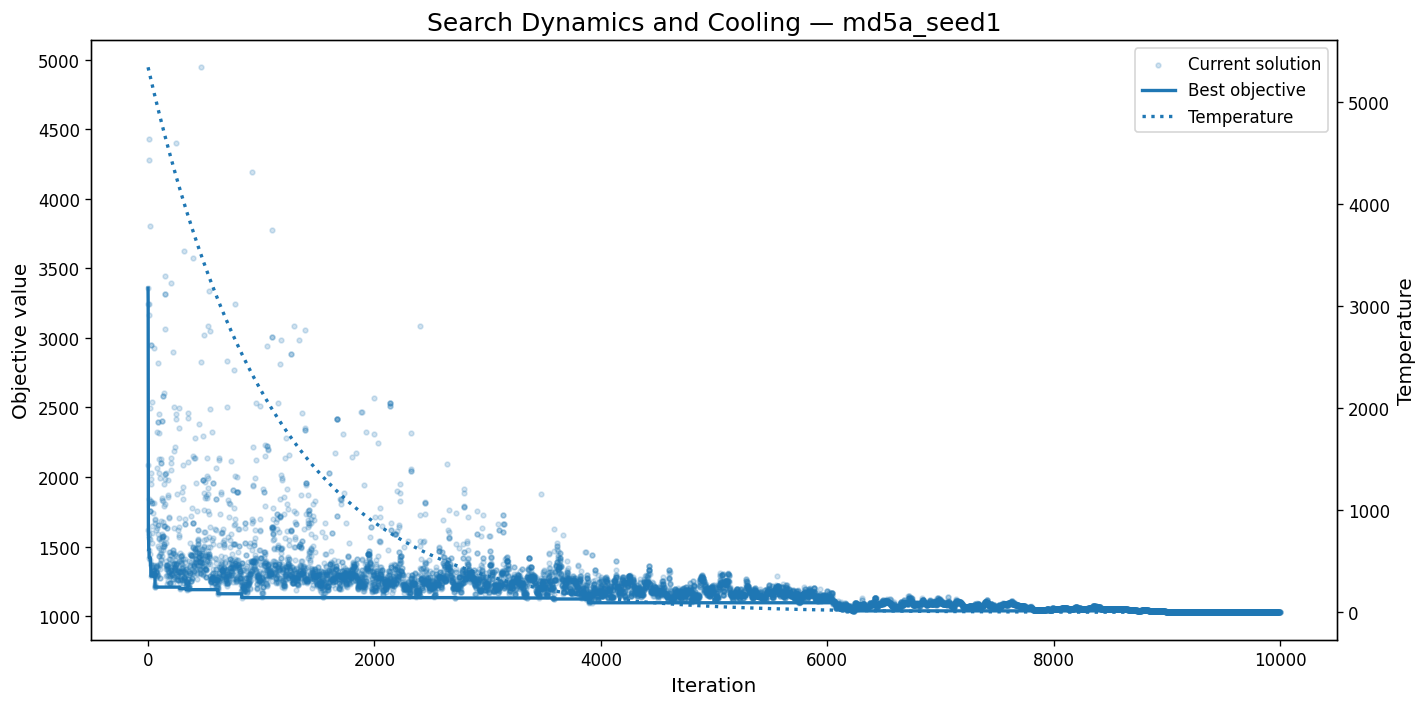

In [31]:
# ---------------------------------------------------------
# Individual acceptance / cooling dynamics
# ---------------------------------------------------------

if not df_selected.empty:
    fig, ax1 = plt.subplots(figsize=(12, 6))

    ax1.scatter(
        df_selected["iteration"],
        df_selected["current_obj"],
        alpha=0.20,
        s=8,
        label="Current solution"
    )

    ax1.plot(
        df_selected["iteration"],
        df_selected["best_obj"],
        label="Best objective"
    )

    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Objective value")

    ax2 = ax1.twinx()
    ax2.plot(
        df_selected["iteration"],
        df_selected["temperature"],
        linestyle=":",
        label="Temperature"
    )
    ax2.set_ylabel("Temperature")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

    ax1.set_title(f"Search Dynamics and Cooling — {selected_run_id}")

    plt.tight_layout()
    plt.show()


In [32]:
# ---------------------------------------------------------
# Individual operator usage
# ---------------------------------------------------------

if not df_selected.empty:
    selected_valid = df_selected[
        df_selected["destroy_op"].isin(DESTROY_METHODS.keys())
        & df_selected["repair_op"].isin(REPAIR_METHODS.keys())
    ].copy()

    selected_valid["destroy"] = selected_valid["destroy_op"].map(DESTROY_METHODS)
    selected_valid["repair"] = selected_valid["repair_op"].map(REPAIR_METHODS)

    print("Destroy operator usage")
    display(
        selected_valid["destroy"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("Selection (%)")
        .to_frame()
    )

    print("Repair operator usage")
    display(
        selected_valid["repair"]
        .value_counts(normalize=True)
        .mul(100)
        .rename("Selection (%)")
        .to_frame()
    )

    pair_counts = (
        selected_valid
        .groupby(["destroy", "repair"])
        .size()
        .reset_index(name="Selections")
    )
    pair_counts["Selection (%)"] = (
        100 * pair_counts["Selections"] / len(selected_valid)
    )

    print("Destroy-repair pair usage")
    display(pair_counts.sort_values("Selections", ascending=False).round(3))


Destroy operator usage


,Selection (%)
destroy,
Worst,37.51
Random,34.53
Shaw,27.96


Repair operator usage


,Selection (%)
repair,
Regret-2,42.88
Regret-3,41.21
Greedy,15.91


Destroy-repair pair usage


,destroy,repair,Selections,Selection (%)
7,Worst,Regret-2,1593,15.93
8,Worst,Regret-3,1558,15.58
1,Random,Regret-2,1524,15.24
2,Random,Regret-3,1404,14.04
4,Shaw,Regret-2,1171,11.71
5,Shaw,Regret-3,1159,11.59
6,Worst,Greedy,600,6.00
0,Random,Greedy,525,5.25
3,Shaw,Greedy,466,4.66


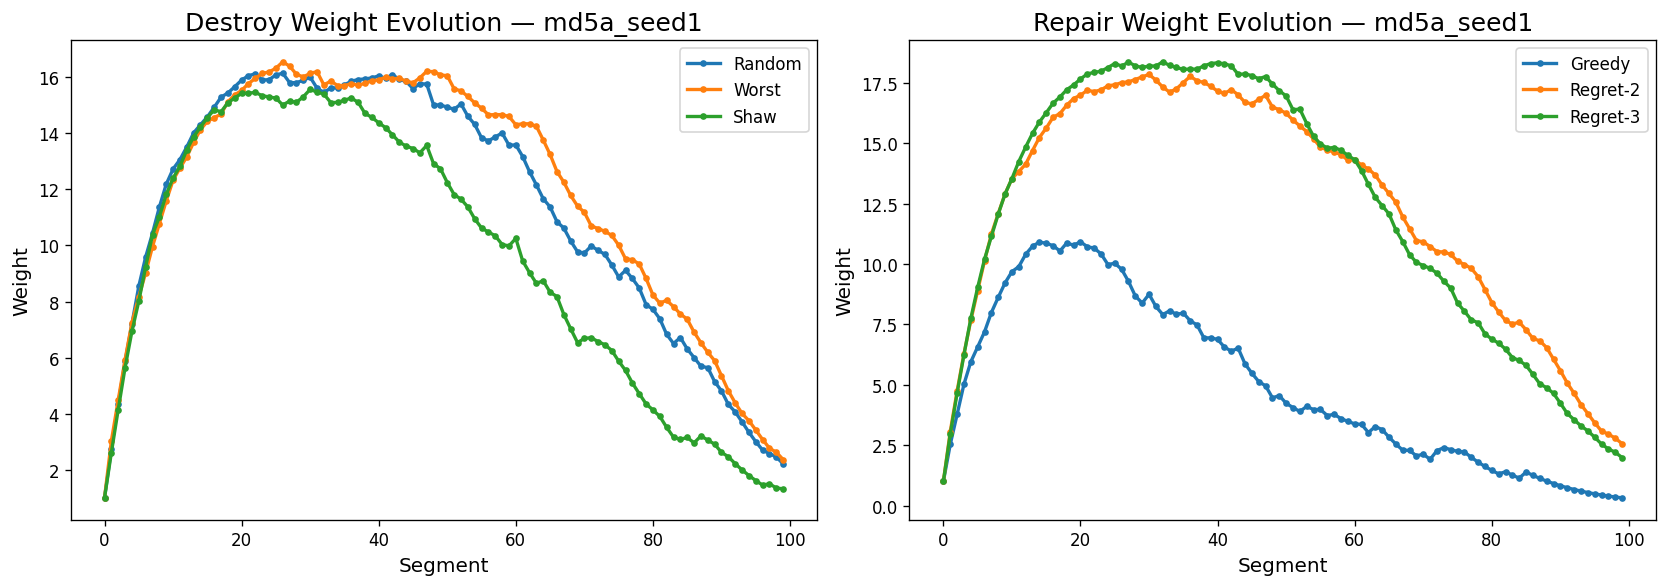

In [33]:
# ---------------------------------------------------------
# Individual weight evolution
# ---------------------------------------------------------

plot_weights_for_run(SELECTED_INSTANCE, SELECTED_SEED)


## 18. Aggregate convergence curves

For aggregation across different instances, raw objective values are not directly comparable because instance sizes differ.

Instead, the curves below use **RPD relative to the best objective observed for that instance in this experiment**.

The first plot aggregates all runs. The second separates regimes A and B.


## 19. Time-to-best analysis

This section asks how quickly the algorithm reaches its best solution.

The key measures are:

- time at which the best solution was first reached;
- percentage of total runtime spent before reaching the best solution.

This can be useful if the paper needs to discuss not only final quality but also convergence speed.


In [34]:
# ---------------------------------------------------------
# Time-to-best statistics
# ---------------------------------------------------------

df_runs["best_time_pct"] = (
    100 * df_runs["best_time_sec"] / df_runs["elapsed_time_sec"]
)

time_to_best_summary = (
    df_runs
    .groupby("instance")
    .agg(
        mean_best_time_sec=("best_time_sec", "mean"),
        median_best_time_sec=("best_time_sec", "median"),
        mean_best_time_pct=("best_time_pct", "mean"),
        median_best_time_pct=("best_time_pct", "median"),
    )
    .reset_index()
)

display(time_to_best_summary.round(3))


,instance,mean_best_time_sec,median_best_time_sec,mean_best_time_pct,median_best_time_pct
0,md10a,5691.777,5240.595,94.094,95.848
1,md10b,5482.482,5070.570,93.943,95.396
2,md1a,10.700,7.835,22.295,15.960
3,md1b,13.952,14.342,24.521,25.942
4,md2a,183.046,174.485,60.374,63.167
5,md2b,170.569,175.528,50.153,50.065
6,md3a,659.582,646.024,75.323,77.454
7,md3b,691.819,625.089,60.421,62.724
8,md4a,1250.884,1251.335,68.398,70.958
9,md4b,1478.906,1500.545,77.223,78.956


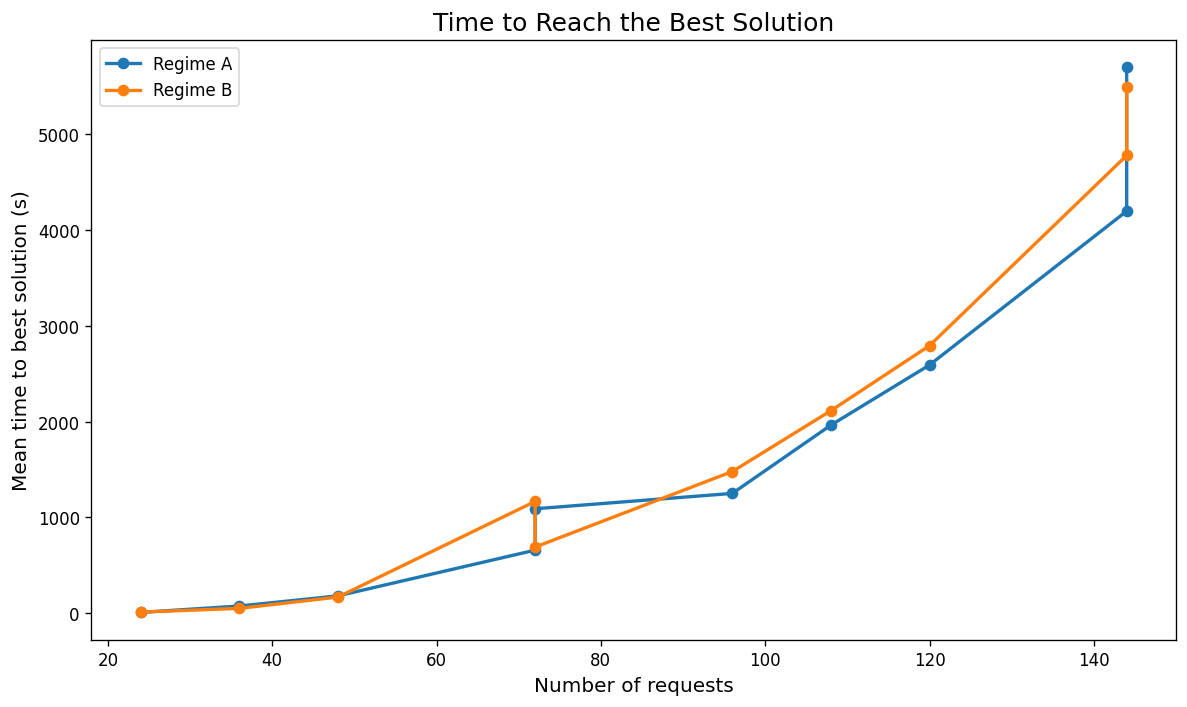

In [35]:
# ---------------------------------------------------------
# Time-to-best plot
# ---------------------------------------------------------

plot_df = (
    time_to_best_summary
    .merge(
        instance_summary[["instance", "n_requests", "regime"]],
        on="instance",
        how="left"
    )
    .sort_values("n_requests")
)

fig, ax = plt.subplots(figsize=(10, 6))

for regime, g in plot_df.groupby("regime"):
    ax.plot(
        g["n_requests"],
        g["mean_best_time_sec"],
        marker="o",
        label=f"Regime {regime}"
    )

ax.set_xlabel("Number of requests")
ax.set_ylabel("Mean time to best solution (s)")
ax.set_title("Time to Reach the Best Solution")
ax.legend()

plt.tight_layout()
plt.show()


## 20. Adaptive weights: final vs. initial values

A compact way of summarizing the adaptive mechanism is to compare the initial and final weights.

This is particularly useful if the weight trajectories are too detailed for the paper.


In [36]:
# ---------------------------------------------------------
# Initial and final adaptive weights
# ---------------------------------------------------------

if not df_weights_all.empty:
    weight_cols = [
        "destroy_weight_0", "destroy_weight_1", "destroy_weight_2",
        "repair_weight_0", "repair_weight_1", "repair_weight_2"
    ]

    initial_rows = (
        df_weights_all
        .sort_values(["run_id", "segment"])
        .groupby("run_id")
        .first(numeric_only=True)
    )

    final_rows = (
        df_weights_all
        .sort_values(["run_id", "segment"])
        .groupby("run_id")
        .last(numeric_only=True)
    )

    initial_weights = initial_rows[weight_cols].mean().rename("Initial mean")
    final_weights = final_rows[weight_cols].mean().rename("Final mean")

    weight_summary = pd.concat(
        [initial_weights, final_weights],
        axis=1
    )

    weight_summary.index = [
        DESTROY_METHODS.get(int(c.split("_")[-1]), c)
        if c.startswith("destroy_")
        else REPAIR_METHODS.get(int(c.split("_")[-1]), c)
        for c in weight_summary.index
    ]

    display(weight_summary.round(4))


,Initial mean,Final mean
Random,1.0,1.1674
Worst,1.0,1.1274
Shaw,1.0,0.7341
Greedy,1.0,0.2818
Regret-2,1.0,1.2424
Regret-3,1.0,0.9862


## 21. Cross-check convergence logs against JSON outputs

This is a consistency check, not a performance metric.

If the JSON objective differs from the convergence-log best feasible objective, inspect those runs before using either value as the definitive final objective.


In [37]:
# ---------------------------------------------------------
# JSON vs convergence-log consistency check
# ---------------------------------------------------------

if not df_solutions.empty:
    consistency = df_runs[
        [
            "run_id",
            "instance",
            "seed",
            "best_feasible_objective",
            "json_objective",
            "elapsed_time_sec",
            "json_time_sec",
            "status"
        ]
    ].copy()

    consistency["objective_difference"] = (
        consistency["json_objective"]
        - consistency["best_feasible_objective"]
    ).abs()

    consistency["time_difference_sec"] = (
        consistency["json_time_sec"]
        - consistency["elapsed_time_sec"]
    ).abs()

    display(
        consistency.sort_values(
            "objective_difference",
            ascending=False
        ).head(20).round(6)
    )

    print(
        "Runs with objective discrepancy > 1e-6:",
        (consistency["objective_difference"] > 1e-6).sum()
    )


,run_id,instance,seed,best_feasible_objective,json_objective,elapsed_time_sec,json_time_sec,status,objective_difference,time_difference_sec
6,md10a_seed16,md10a,16,1186.82,1186.82487,5371.71,5371.713615,Feasible,0.00487,0.003615
245,md6a_seed15,md6a,15,1254.50,1254.49516,4485.36,4485.360643,Feasible,0.00484,0.000643
5,md10a_seed15,md10a,15,1190.11,1190.10524,5295.37,5295.369166,Feasible,0.00476,0.000834
250,md6a_seed1,md6a,1,1206.75,1206.74528,4509.66,4509.665322,Feasible,0.00472,0.005322
274,md6b_seed4,md6b,4,1070.08,1070.07530,6456.61,6456.614668,Feasible,0.00470,0.004668
16,md10a_seed6,md10a,6,1212.81,1212.80533,7200.12,7200.123473,Feasible,0.00467,0.003473
260,md6b_seed10,md6b,10,1052.22,1052.22460,4538.84,4538.842053,Feasible,0.00460,0.002053
33,md10b_seed3,md10b,3,1153.78,1153.77540,5333.26,5333.263126,Feasible,0.00460,0.003126
12,md10a_seed2,md10a,2,1212.41,1212.40541,5223.28,5223.287659,Feasible,0.00459,0.007659
215,md5a_seed5,md5a,5,1020.82,1020.82450,4023.39,4023.397339,Feasible,0.00450,0.007339


Runs with objective discrepancy > 1e-6: 399


## 22. Export useful tables

The notebook keeps all intermediate dataframes in memory, but the following cell exports the most useful tables for further analysis or inclusion in the paper.


In [38]:
# ---------------------------------------------------------
# Export analysis tables
# ---------------------------------------------------------

exports = {
    "run_summary.csv": df_runs,
    "instance_summary.csv": instance_summary,
    "instance_rpd_summary.csv": instance_rpd_summary,
    "main_performance_table.csv": main_table,
    "global_summary.csv": global_summary,
    "regime_summary.csv": regime_summary,
    "operator_selection.csv": operator_selection_table,
    "pair_selection.csv": pair_selection_summary,
    "pair_reward.csv": pair_reward,
    "destroy_selection_by_regime.csv": destroy_regime_summary,
    "repair_selection_by_regime.csv": repair_regime_summary,
    "destroy_selection_by_size.csv": destroy_size_summary,
    "repair_selection_by_size.csv": repair_size_summary,
    "time_to_best.csv": time_to_best_summary,
}

for filename, table in exports.items():
    table.to_csv(ANALYSIS_DIR / filename, index=False)

print(f"Exported {len(exports)} analysis tables to:")
print(ANALYSIS_DIR.resolve())


Exported 14 analysis tables to:
/home/guillem/MD-DARP-Research-clean/experiments/results/base_20


# Suggested paper candidates

The notebook intentionally generates more information than should appear in the paper.

For the **~5-page results section**, I would initially shortlist:

### Main results
- `main_performance_table.csv`
- mean RPD by instance
- runtime vs. number of requests

### ALNS component analysis
- destroy/repair selection-frequency table
- one compact plot of adaptive weights or operator selection
- evaluator comparison and local-search ablation from the corresponding experiments

### Matheuristic analysis
- ALNS vs. ALNS + SP vs. ALNS + SC

### Validation
- R-series comparison

### Discussion
- tight (`a`) vs. loose (`b`) time windows
- whether operator preferences change with instance size

The detailed pair-reward distributions, individual-run convergence plots, and full weight trajectories are mainly intended as diagnostic/exploratory material.
